# 01. DRAM 스펙과 셀 기본 물리 (D1)

설계는 **목표(스펙)를 먼저 정하는 것**에서 시작합니다. 이 노트북에서는
1. DRAM 셀이 데이터를 저장하고 잃는 원리를 보고,
2. 스펙 표를 정하고,
3. **슬라이더로 설계 값을 바꿔 가며** 스펙을 만족하는지 직접 확인합니다.

**실행 방법**: 메뉴에서 **런타임 → 모두 실행**.

> 모든 수치는 가정값과 시뮬레이션입니다. 실제 제품 값이 아닙니다. 사용한 가정은 맨 아래 표에 있습니다.

In [1]:
import os, sys, subprocess
BRANCH = "claude/feature-research"
if "google.colab" in sys.modules:
    if not os.path.isdir("/content/dsadsa"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", BRANCH,
                        "https://github.com/tjrgns1753-create/dsadsa", "/content/dsadsa"], check=True)
    else:
        subprocess.run(["git", "-C", "/content/dsadsa", "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/dsadsa"], check=True)
    sys.path.insert(0, "/content/dsadsa")
from memdev.colab import setup
status = setup(install=True)
print(status)

{'ngspice': True, 'devsim': True, 'korean_font': True}


## 1. 비유: 구멍 난 물컵

- DRAM 셀 하나 = **작은 물컵(커패시터 Cs)** 과 **수도꼭지(접근 트랜지스터)**
- 물 = 전하, 물 높이 = **셀 전압**. 가득(Vdd)이면 '1', 비면 '0'
- 컵에 아주 작은 구멍이 있어 물이 샙니다 → **누설 전류**

**읽을 때 일어나는 일 (전하 분배)**: 셀을 읽으면 컵의 물이 훨씬 큰 통(비트라인, Cbl)과 섞입니다.
비트라인은 미리 Vdd/2로 맞춰 두기 때문에, 셀이 '1'이면 비트라인 전압이 **아주 조금** 오릅니다.

$$\Delta V = (V_{cell} - V_{dd}/2)\cdot\frac{C_s}{C_s + C_{bl}}$$

센스앰프는 이 작은 신호(수십 mV)를 증폭해서 0/1을 판단합니다. 신호가 최소값보다 작으면 구분하지 못합니다.
그래서 셀 전압이 어떤 값(**읽기 실패 전압**) 아래로 떨어지면 데이터를 잃은 것입니다.

$$V_{fail} = V_{dd}/2 + \Delta V_{min}\cdot\frac{C_s + C_{bl}}{C_s}$$

## 2. 스펙 (D1)
현업에서는 설계 전에 이런 표를 먼저 정합니다. 아래 값은 출발점이 되는 **가정**입니다.

In [2]:
from memdev.dram.spec import DramSpec, check_retention, check_signal, spec_table

SPEC = DramSpec()
print(f"{'항목':8s} | {'목표':45s} | 의미")
for item, target, meaning in spec_table(SPEC):
    print(f"{item:8s} | {target:45s} | {meaning}")

항목       | 목표                                            | 의미
리텐션      | 85°C에서 64 ms 이상 (예비 셀 수리 후, 칩 기준)             | 리프레시 주기 안에 데이터 유지
읽기 신호    | 비트라인 신호 ≥ 50 mV                               | 센스앰프가 구분할 수 있는 최소 신호
쓰기       | 쓰기 펄스 10 ns 안에 셀 전압이 목표의 95% 도달               | 접근 트랜지스터가 충분히 켜짐
동작 조건    | 0~95°C, 전원 ±5%                                | 코너 검증 범위
수리 한도    | 가정 1000셀 (근거 미확인, D6 민감도)                     | 수율 판정 기준


## 3. 기준 설계에서 시간에 따른 셀 전압
기준 파라미터 세트 `dram_baseline`으로 온도별 셀 전압 감쇠와 리텐션을 계산합니다.

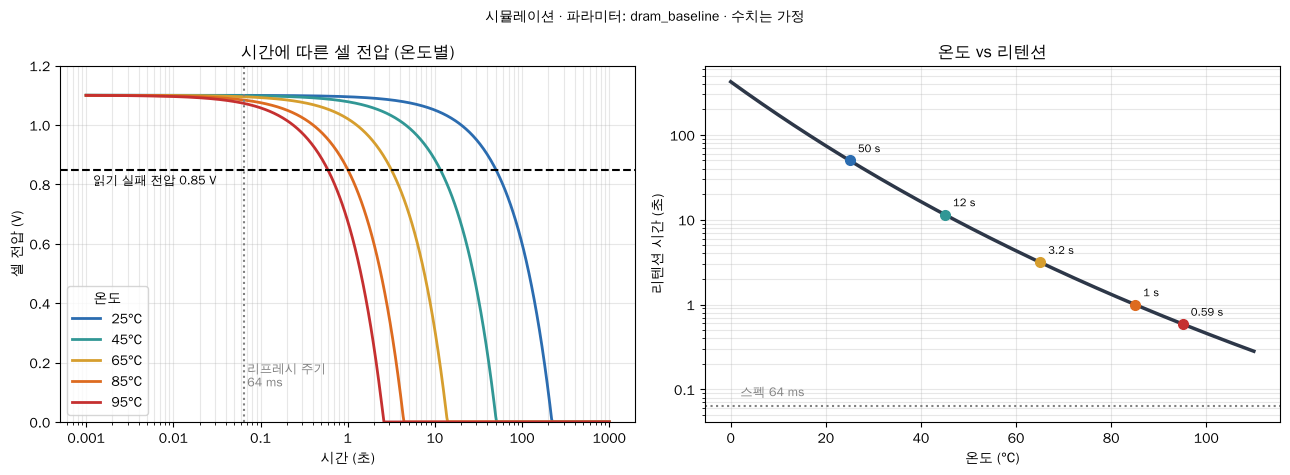

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from memdev.dram.cell import bitline_signal, cell_voltage, fail_voltage, retention_time
from memdev.dram.leakage import arrhenius_leakage
from memdev.params import load_params, values
from memdev.plotting import plain_log_ticks, sim_label

P = values("dram_baseline")
V_FAIL = fail_voltage(P["vdd"], P["cs"], P["cbl"], P["sense_min"])
TEMPS = [25, 45, 65, 85, 95]
COLORS = ["#2b6cb0", "#319795", "#d69e2e", "#dd6b20", "#c53030"]


def leak(temp_c, i_ref=P["i_leak_ref"], ea=P["ea"]):
    return arrhenius_leakage(temp_c, i_ref, P["t_ref_c"], ea)


t = np.logspace(-3, 3, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for temp, color in zip(TEMPS, COLORS):
    ax1.plot(t, cell_voltage(t, P["vdd"], leak(temp), P["cs"]), color=color, lw=2, label=f"{temp}°C")
ax1.axhline(V_FAIL, ls="--", color="black")
ax1.text(1.2e-3, V_FAIL - 0.05, f"읽기 실패 전압 {V_FAIL:.2f} V", fontsize=9)
ax1.axvline(P["t_refresh"], ls=":", color="gray")
ax1.text(P["t_refresh"] * 1.1, 0.12, "리프레시 주기\n64 ms", fontsize=9, color="gray")
ax1.set_xscale("log"); plain_log_ticks(ax1.xaxis)
ax1.set_ylim(0, 1.2)
ax1.set_xlabel("시간 (초)"); ax1.set_ylabel("셀 전압 (V)")
ax1.set_title("시간에 따른 셀 전압 (온도별)")
ax1.legend(title="온도"); ax1.grid(alpha=0.3, which="both")

temp_axis = np.linspace(0, 110, 200)
t_ret = retention_time(P["vdd"], V_FAIL, leak(temp_axis), P["cs"])
ax2.plot(temp_axis, t_ret, color="#2d3748", lw=2.5)
for temp, color in zip(TEMPS, COLORS):
    r = retention_time(P["vdd"], V_FAIL, leak(temp), P["cs"])
    ax2.plot(temp, r, "o", color=color, ms=7)
    ax2.annotate(f"{r:.2g} s", (temp, r), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax2.axhline(SPEC.retention_min_s, ls=":", color="gray")
ax2.text(2, SPEC.retention_min_s * 1.3, "스펙 64 ms", fontsize=9, color="gray")
ax2.set_yscale("log"); plain_log_ticks(ax2.yaxis)
ax2.set_xlabel("온도 (°C)"); ax2.set_ylabel("리텐션 시간 (초)")
ax2.set_title("온도 vs 리텐션"); ax2.grid(alpha=0.3, which="both")
fig.suptitle(sim_label("dram_baseline"), fontsize=10)
fig.tight_layout()
plt.show()

**읽는 법**
- 왼쪽: 각 선이 검은 점선(읽기 실패 전압)과 만나는 시점이 그 온도의 리텐션 시간입니다.
- 오른쪽: 세로축이 10배씩 늘어나는 눈금인데 거의 직선입니다. 온도가 오르면 리텐션이 **일정 비율로** 줄어든다는 뜻이고,
  누설이 온도에 지수적으로 민감하기 때문입니다(**아레니우스 법칙**).

## 4. 직접 바꿔 보기 (슬라이더)

| 슬라이더 | 뜻 | 늘리면 |
|---|---|---|
| Cs | 셀 커패시터 (컵 크기) | 물이 많아 오래 버팀, 신호도 커짐 |
| Cbl | 비트라인 커패시턴스 (큰 통) | 신호가 묽어져 작아짐 |
| 누설 @85°C | 85°C에서 구멍 크기 | 빨리 샘 |
| 온도 | 동작 온도 | 누설이 지수적으로 증가 |
| Ea | 활성화 에너지 (온도 민감도) | 온도에 더 민감 |
| 최소 신호 | 센스앰프가 구분하는 최소 신호 | 읽기 실패 전압이 올라감 |

슬라이더를 움직이면 아래 그래프와 판정이 바로 바뀝니다. (Colab에서 실행할 때 동작합니다.)

In [4]:
import ipywidgets as w
from IPython.display import display


def explore(cs_fF=10.0, cbl_fF=50.0, leak85_fA=2.5, temp_c=85, ea_eV=0.6, sense_mV=50):
    cs, cbl, vdd = cs_fF * 1e-15, cbl_fF * 1e-15, P["vdd"]
    smin = sense_mV * 1e-3
    i_ref = leak85_fA * 1e-15
    vf = fail_voltage(vdd, cs, cbl, smin)
    dv = float(bitline_signal(vdd, vdd, cs, cbl))
    t_now = retention_time(vdd, vf, leak(temp_c, i_ref, ea_eV), cs)
    t_spec = retention_time(vdd, vf, leak(SPEC.retention_temp_c, i_ref, ea_eV), cs)
    r_ret, r_sig = check_retention(t_spec, SPEC), check_signal(dv, SPEC)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(t, cell_voltage(t, vdd, leak(temp_c, i_ref, ea_eV), cs), lw=2.5, color="#2b6cb0")
    if vf < 1.2:
        ax.axhline(vf, ls="--", color="black")
    ax.axvline(SPEC.retention_min_s, ls=":", color="gray")
    ax.set_xscale("log"); plain_log_ticks(ax.xaxis)
    ax.set_ylim(0, 1.2)
    ax.set_xlabel("시간 (초)"); ax.set_ylabel("셀 전압 (V)")
    ax.set_title(f"{temp_c}°C에서 셀 전압 · " + sim_label("dram_baseline + 슬라이더"), fontsize=9)
    ax.grid(alpha=0.3, which="both")
    plt.show()

    def verdict(r):
        return f"{'통과' if r.passed else '실패'} (여유 {r.margin:.2g}배)"

    if vf >= vdd:
        print(f"읽기 불가: 가득 찬 셀의 신호 {dv * 1e3:.1f} mV가 최소 감지값 {sense_mV} mV보다 작습니다.")
    print(f"읽기 실패 전압: {vf:.3f} V,  가득 찬 셀의 신호: {dv * 1e3:.1f} mV → 읽기 신호 스펙 {verdict(r_sig)}")
    print(f"{temp_c}°C 리텐션: {t_now:.3g} s")
    print(f"스펙 조건({SPEC.retention_temp_c:g}°C) 리텐션: {t_spec:.3g} s → 리텐션 스펙 {verdict(r_ret)}")


display(w.interactive(
    explore,
    cs_fF=w.FloatSlider(value=10, min=2, max=30, step=1, description="Cs (fF)"),
    cbl_fF=w.FloatSlider(value=50, min=10, max=200, step=5, description="Cbl (fF)"),
    leak85_fA=w.FloatLogSlider(value=2.5, base=10, min=-1, max=2, description="누설@85°C (fA)"),
    temp_c=w.IntSlider(value=85, min=0, max=110, step=5, description="온도 (°C)"),
    ea_eV=w.FloatSlider(value=0.6, min=0.3, max=1.2, step=0.05, description="Ea (eV)"),
    sense_mV=w.IntSlider(value=50, min=20, max=150, step=5, description="최소 신호 (mV)"),
))

interactive(children=(FloatSlider(value=10.0, description='Cs (fF)', max=30.0, min=2.0, step=1.0), FloatSlider…

## 5. 이상한 점: 1초를 버티는데 왜 64 ms마다 리프레시할까?

기준 셀은 85°C에서 약 **1초**를 버팁니다. 스펙(64 ms)보다 15배 이상 여유가 있습니다.
그런데 실제 DRAM은 64 ms마다 리프레시합니다.

이 그래프는 **평범한 셀 하나**이기 때문입니다. 칩에는 셀이 수십억 개 있고, 공정 편차 때문에 **일부는 훨씬 빨리 새는 약한 셀**입니다.
리프레시 주기는 평균이 아니라 **가장 약한 셀**에 맞춰야 합니다.
→ M5(산포와 수율)에서 셀 수백만 개를 만들어 이 꼬리를 직접 다루고, M6에서 결론 질문(약한 셀이 있는 행만 자주 리프레시하기)에 답합니다.

## 6. 면접에서 이렇게 말할 수 있습니다

> "DRAM 셀은 커패시터에 저장한 전하가 누설로 빠져나가서, 읽을 때 비트라인과 전하를 나눈 신호가 센스앰프의 최소 감지값 아래로 떨어지기 전에 리프레시해야 합니다.
> 신호 크기는 Cs/(Cs+Cbl) 비에 비례해서 Cs가 작아지면 리텐션과 신호가 함께 나빠집니다.
> 누설은 온도에 지수적으로 증가해 고온에서 리텐션이 급격히 짧아지고, 리프레시 주기는 평균 셀이 아니라 분포 꼬리의 약한 셀이 정합니다."

## 7. 사용한 가정

In [5]:
print(f"{'키':12s} | {'값':>10s} | {'단위':6s} | {'상태':8s} | 출처")
for key, p in load_params("dram_baseline").items():
    print(f"{key:12s} | {p.value:10.3g} | {p.unit:6s} | {p.status:8s} | {p.source}")

키            |          값 | 단위     | 상태       | 출처
cs           |      1e-14 | F      | assumed  | 시험작 가정값, 공개 자료 확인 전
cbl          |      5e-14 | F      | assumed  | 시험작 가정값, 공개 자료 확인 전
vdd          |        1.1 | V      | assumed  | 시험작 가정값, 공개 자료 확인 전
sense_min    |       0.05 | V      | assumed  | 시험작 가정값, 공개 자료 확인 전
i_leak_ref   |    2.5e-15 | A      | assumed  | 시험작 가정값, 공개 자료 확인 전 (t_ref_c에서의 셀 누설)
t_ref_c      |         85 | degC   | assumed  | 시험작 가정값, 공개 자료 확인 전
ea           |        0.6 | eV     | assumed  | 시험작 가정값, 공개 자료 확인 전
t_refresh    |      0.064 | s      | assumed  | 시험작 가정값, 공개 자료 확인 전
write_pulse  |      1e-08 | s      | assumed  | 시험작 가정값, 공개 자료 확인 전
repair_limit |      1e+03 | cells  | assumed  | 근거 미확인 가정값, D6에서 민감도로 다룸
